In [208]:
!pip install tqdm bs4 requests fake_useragent free-proxy pandas musicbrainzngs

In [209]:
from tqdm import tqdm
from bs4 import BeautifulSoup
import requests
from fake_useragent import UserAgent
from fp.fp import FreeProxy
import re
import time
import random
import os
import pandas as pd
import musicbrainzngs

In [172]:
ua = UserAgent()

headers = {"User-Agent": 'Mozilla/5.0 (iPhone; CPU iPhone OS 18_2 like Mac OS X) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/18.2 Mobile/15E148 Safari/604.1'}
proxy_url = FreeProxy(timeout=1,
                      rand=True).get()

print(f"Using working proxy: {proxy_url}")
proxies = {
    "http": proxy_url,
    "https": proxy_url,
}

response = requests.get('https://www.azlyrics.com/t/taylorswift.html', 
                        headers=headers, proxies=proxies)
path_page = BeautifulSoup(response.text, 'html.parser')

Using working proxy: http://4.144.146.21:80


<!DOCTYPE html>

<html lang="en">
<head>
<meta charset="utf-8"/>
<meta content="IE=edge" http-equiv="X-UA-Compatible"/>
<meta content="width=device-width, initial-scale=1" name="viewport"/>
<!-- The above 3 meta tags *must* come first in the head; any other head content must come *after* these tags -->
<meta content='Taylor Swift lyrics - 487 song lyrics sorted by album, including "Cleveland!", "Patient Zero", "Babylon".' name="description"/>
<meta content="Taylor Swift, Taylor Swift lyrics, discography, albums, songs" name="keywords"/>
<meta content="noarchive" name="robots"/>
<title>Taylor Swift Lyrics</title>
<link href="https://www.azlyrics.com/t/taylorswift.html" rel="canonical"/>
<link href="https://maxcdn.bootstrapcdn.com/bootstrap/3.3.4/css/bootstrap.min.css" rel="stylesheet"/>
<link href="/local/az.css" rel="stylesheet"/>
<link href="https://static.cheftoondiligord.site/static/assets/style.min.css?t=1762447466" rel="stylesheet"/>
<!-- HTML5 shim and Respond.js for IE8 support 
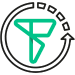
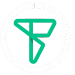

In [173]:
path_page

In [174]:
errors = []
not_needed = []
main_path = 'https://www.azlyrics.com'
all_songs = path_page.find_all('div', class_='listalbum-item')

for song_i in tqdm(all_songs):
    if 'azlyrics' not in song_i.a['href']:
        song_link = main_path + song_i.a['href']
    else:
        song_link = song_i.a['href']
    
    song_name = song_i.text

    if f'{song_name}.txt' in os.listdir('.lyrics/'):
        continue

    if "Taylor's Version" in song_name:
        if "(From The Vault)" not in song_name:
            not_needed.append(song_name)
            continue
    if 'Remix' in song_name:
        not_needed.append(song_name)
        continue
    if 'Sad Girl Autumn Version' in song_name:
        not_needed.append(song_name)
        continue
    if 'Music-Video Version' in song_name:
        not_needed.append(song_name)
        continue
    if 'Music Video Version' in song_name:
        not_needed.append(song_name)
        continue
    if 'Acoustic' in song_name:
        not_needed.append(song_name)
        continue
    if 'Demo' in song_name:
        not_needed.append(song_name)
        continue
    if 'Piano Version' in song_name:
        not_needed.append(song_name)
        continue
    if 'Live from' in song_name:
        not_needed.append(song_name)
        continue
    if 'Tour Live' in song_name:
        not_needed.append(song_name)
        continue
    if 'World Tour' in song_name:
        not_needed.append(song_name)
        continue
    if 'A Message From Taylor' in song_name:
        not_needed.append(song_name)
        continue
    if 'Meet Me At Midnight' in song_name:
        not_needed.append(song_name)
        continue

    try:
        song_data = requests.get(song_link, headers=headers, proxies=proxies)
        song_page = BeautifulSoup(song_data.text, 'html.parser')
        with open(f'.lyrics/{song_name}.txt', 'w') as f:
            print(song_page, file=f)
        time.sleep(random.uniform(1.5, 5))
    except:
        errors.append(song_link)
print(errors)

  0%|          | 0/487 [00:00<?, ?it/s]

100%|██████████| 487/487 [01:29<00:00,  5.44it/s]

[]


In [175]:
print(not_needed[:10])

['Forever & Always (Piano Version)(Platinum Edition)', "Fearless (Taylor's Version)", "Fifteen (Taylor's Version)", "Love Story (Taylor's Version)", "Hey Stephen (Taylor's Version)", "White Horse (Taylor's Version)", "You Belong With Me (Taylor's Version)", "Breathe (Taylor's Version)", "Tell Me Why (Taylor's Version)", "You're Not Sorry (Taylor's Version)"]


In [ ]:
with open('pen_categories/fountain pen.txt') as f:
    fountain_pen = list(map(lambda x: x.strip(), 
                            f.readlines()))
with open('pen_categories/glitter gel pen.txt') as f:
    glitter_pen = list(map(lambda x: x.strip(), 
                            f.readlines()))
with open('pen_categories/quill pen.txt') as f:
    quill_pen = list(map(lambda x: x.strip(), 
                            f.readlines()))

path_list = []
artist_name_list = []
song_name_list = []
song_writers_list = []
song_album_list = []
song_year_list = []
song_lyrics_list = []
song_category_list = []
    
for song_i in tqdm(os.listdir('.lyrics/')):
    with open(f'.lyrics/{song_i}') as f:
        path_list.append(song_i)
        txt_page = BeautifulSoup(f.read(), 'html.parser')
        try:
            artist_name = re.search('(?<=ArtistNameNc = ").*(?=";)',
                                txt_page.find_all('script')[1].text).group()
        except:
            artist_name = pd.NA
        try:
            song_name = re.search('(?<=SongNameNc = ").*(?=";)',
                                txt_page.find_all('script')[1].text).group()
            if song_name in fountain_pen:
                song_category = 'Fountain Pen'
            elif song_name in glitter_pen:
                song_category = 'Glitter Gel Pen'
            elif song_name in quill_pen:
                song_category = 'Quill Pen'
            else:
                song_category = pd.NA
        except:
            song_name = pd.NA
            song_category = pd.NA
        try:
            song_writers = re.search('(?<=Writer\\(s\\):).*',
                                     txt_page.text).group().strip().split(',')
        except:
            song_writers = pd.NA
        try:
            song_album = txt_page.find_all('div', class_='songinalbum_title')[0].text
            if 'You May Also Like' not in song_album:
                song_year = int(re.search('(?<=\\()[0-9]+',
                                    song_album).group())
                song_album = re.search('(?<=").*(?=")',
                                    song_album).group()
            else:
                song_year = pd.NA
                song_album = pd.NA
        except:
            song_album = pd.NA
            song_year = pd.NA
        
        try:
            song_lyrics = txt_page.text.split('\n\n\n\n')[28].replace('\n\n', '\n').split('\n')
        except:
            song_lyrics = pd.NA
        

        artist_name_list.append(artist_name)
        song_name_list.append(song_name)
        song_writers_list.append(song_writers)
        song_album_list.append(song_album)
        song_year_list.append(song_year)
        song_lyrics_list.append(song_lyrics)
        song_category_list.append(song_category)

dataset = pd.DataFrame(
    {
        'Artist': artist_name_list,
        'Song Name': song_name_list,
        'Writers': song_writers_list,
        'Album': song_album_list,
        'Release Year': song_year_list,
        'Lyrics': song_lyrics_list,
        'Pen Category': song_category_list,
        'Path': path_list
    }
)
     
        

100%|██████████| 379/379 [00:06<00:00, 58.73it/s]


In [214]:
print(f'The size of the dataset is {dataset.shape[0]}',
      'Among this:',
      f'{dataset[dataset['Song Name'].notna()].shape[0]} entries include the song name',
      f'{dataset[dataset['Lyrics'].notna()].shape[0]} entries include the song lyrics',
      f'{dataset[dataset['Writers'].notna()].shape[0]} entries include the song name',
      f'{dataset[dataset['Album'].notna()].shape[0]} entries include the album name',
      f'{dataset[dataset['Release Year'].notna()].shape[0]} entries include the release year',
      f'{dataset[dataset['Pen Category'].notna()].shape[0]} entries include the pen category name',
      sep = '\n')
dataset.to_csv('.data/dataset.csv', index=False)

The size of the dataset is 379
Among this:
379 entries include the song name
379 entries include the song lyrics
277 entries include the song name
273 entries include the album name
273 entries include the release year
55 entries include the pen category name


In [210]:
musicbrainzngs.set_useragent("Example music app", "0.1", "http://example.com/music")

In [211]:
result = musicbrainzngs.search_artists(artist="Taylor Swift")
for artist in result['artist-list']:
    print(u"{id}: {name}".format(id=artist['id'], name=artist["name"]))

20244d07-534f-4eff-b4d4-930878889970: Taylor Swift
107d0c22-d051-4d98-8206-4e14de02132a: James Taylor
5f33e650-79d0-4274-b730-74e985f94205: Charles Taylor
0d06bb57-c3b6-4188-9b73-826c41c3e29e: Cecil Taylor
4c1c21bc-56d9-4bed-8b58-360b08e76ffa: Johnnie Taylor
c0cd3de7-4654-482b-913b-6fd7dc4ce9a4: Taylor Dayne
0485e73e-54fd-4613-8682-88c969333718: Ian Taylor
607a36bb-e965-486d-b9ae-f635ba53c1b4: Swift Guad
4fb7be42-860c-401c-8ec3-0163a93018ff: Taylor Swift
92ebb02d-2906-4a6d-9e43-21e16b877fa1: Martin Taylor
2f20bb6a-9eb4-419c-8ec8-77446da0d466: Mampi Swift
9ebffe22-c6e0-49bc-a6c2-f79a97bc38b3: Koko Taylor
df66124c-0c71-40ca-b5c1-0992c1f57f39: Chip Taylor
b9a8c773-973b-4a0f-8f4e-c21775abf4c5: Rob Swift
558302b1-07ae-4be1-9edb-2a2b1f036313: Roger Taylor
dab5cf68-b079-4f84-bb1a-888600cbf4db: Taylor Deupree
1dfc8ffd-559e-4a61-bb67-5fabf250a60e: Taylor Davis
dd5f8909-245d-458b-833a-cd6b698399ce: Richard Swift
3d19ffbe-ce69-4adb-9f50-d0c555b063ca: Livingston Taylor
80855d0f-b173-432a-8882-178c

In [212]:
result = musicbrainzngs.get_artist_by_id('20244d07-534f-4eff-b4d4-930878889970',
              includes=["release-groups"], release_type=["album", "ep", "single"])
for release_group in result["artist"]["release-group-list"]:
    print("{title} ({type})".format(title=release_group["title"],
                                    type=release_group["type"]))

Taylor Swift (Album)
Fearless (Album)
Speak Now (Album)
Red (Album)
1989 (Album)
reputation (Album)
Lover (Album)
folklore (Album)
evermore (Album)
Fearless (Taylor’s version) (Album)
Red (Taylor’s version) (Album)
Midnights (Album)
Speak Now (Taylor’s version) (Album)
1989 (Taylor’s version) (Album)
THE TORTURED POETS DEPARTMENT (Album)
The Life of a Showgirl (Album)
Complete Album Collection (Compilation)
reputation Stadium Tour Surprise Song Playlist (Compilation)
Speak Now: World Tour Live (Live)
Live From Clear Channel Stripped 2008 (Live)
Lover (live from Paris) (Live)
folklore: the long pond studio sessions (Live)
Taylor Swift Karaoke: Taylor Swift (Remix)
Taylor Swift Karaoke: Fearless (Remix)
Taylor Swift Karaoke: Speak Now (Remix)


In [213]:
help(musicbrainzngs.get_artist_by_id)

Help on function get_artist_by_id in module musicbrainzngs.musicbrainz:

get_artist_by_id(id, includes=[], release_status=[], release_type=[])
    Get the artist with the MusicBrainz `id` as a dict with an 'artist' key.

    *Available includes*: recordings, releases, release-groups, works, various-artists, discids, media, isrcs, aliases, annotation, area-rels, artist-rels, label-rels, place-rels, event-rels, recording-rels, release-rels, release-group-rels, series-rels, url-rels, work-rels, instrument-rels, tags, user-tags, ratings, user-ratings

